# TP NLP : classification de textes avec TF-IDF et Word2Vec sur trois types de textes

Membres de l'équipe : Prénom NOM, Prénom NOM

## Objectif

Comparer plusieurs façons de prétraiter et de représenter des textes pour une tâche de classification, sur trois types de textes : des articles, des tweets et des commentaires.

| Étape | Contenu |
|---|---|
| 1 | Récupération de trois jeux de données labellisés (articles, tweets, commentaires) |
| 2 | Prétraitement : suppression des stopwords, stemming, lemmatisation |
| 3 | Représentation TF-IDF et Word2Vec |
| 4 | Classification par régression logistique et comparaison des résultats, entre représentations et entre jeux de données |

Nous reprenons la démarche Bag of Words, TF-IDF, stemming, lemmatisation et Word2Vec Skip-gram, CBOW, GloVe pré-entraîné. Et nous appliquons les mêmes étapes à chaque jeu de données. Cela permet de voir quelles conclusions se répètent et lesquelles dépendent du type de texte.

## 0. Installation et imports

In [1]:
%pip install gensim nltk pandas numpy matplotlib scikit-learn datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
from functools import lru_cache

import gensim
from gensim.models import Word2Vec
import gensim.downloader as api
import nltk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from IPython.display import display
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
import warnings
warnings.filterwarnings('ignore')

print("Imports réussis")
print(f"Version de Gensim: {gensim.__version__}")

c:\Users\karlj\AppData\Local\spyder-6\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports réussis
Version de Gensim: 4.4.0


In [3]:
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
print("Ressources NLTK téléchargées")

Ressources NLTK téléchargées


## 1. Jeux de données

Nous utilisons trois jeux de données labellisés, un par type de texte de l'énoncé.

| Type de texte | Jeu de données | Tâche | Classes |
|---|---|---|---|
| Articles | 20 Newsgroups (scikit-learn) | thème de l'article | 4 classes : comp.graphics, rec.sport.hockey, sci.space, talk.politics.mideast |
| Tweets | tweet_eval, configuration sentiment (Hugging Face) | sentiment du tweet | 3 classes : négatif, neutre, positif |
| Commentaires | critiques de films IMDB (Hugging Face) | sentiment de la critique | 2 classes : négatif, positif |

Le jeu Kaggle indiqué dans l'énoncé n'étant pas accessible, nous avons utilisé ces trois jeux, téléchargeables librement. Le jeu tweet_eval contient 45 615 tweets d'entraînement et 12 284 de test, le jeu IMDB 25 000 critiques d'entraînement et 25 000 de test.

Pour garder des temps de calcul raisonnables, les tweets : 4000 en entraînement, 1500 en test et les critiques : 3000 en entraînement, 1000 en test, sont sous-échantillonnés de façon stratifiée, les proportions de classes sont conservées. Les tweets et les critiques sont aussi nettoyés avec balises HTML, adresses web, mentions, symbole dièse.

In [4]:
def clean_web_text(text):
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+|\bhttps?\b', ' ', text)
    text = re.sub(r'@\w+', ' ', text)
    return text.replace('#', ' ')

def stratified_subsample(texts, labels, n, seed=42):
    texts = np.array(texts, dtype=object)
    labels = np.array(labels)
    if len(texts) <= n:
        return list(texts), labels
    rng = np.random.RandomState(seed)
    idx = []
    for c in np.unique(labels):
        ci = np.where(labels == c)[0]
        k = int(round(n * len(ci) / len(labels)))
        idx.extend(rng.choice(ci, size=min(k, len(ci)), replace=False))
    idx = np.array(idx)
    rng.shuffle(idx)
    return list(texts[idx]), labels[idx]

print("Fonctions de nettoyage et d'échantillonnage définies")

Fonctions de nettoyage et d'échantillonnage définies


In [ ]:
categories = ['sci.space', 'rec.sport.hockey', 'talk.politics.mideast', 'comp.graphics']

print("Chargement de 20 Newsgroups")
articles_train = fetch_20newsgroups(
    subset='train',
    categories=categories,
    shuffle=True,
    random_state=42,
    remove=('headers', 'footers', 'quotes')
)

articles_test = fetch_20newsgroups(
    subset='test',
    categories=categories,
    shuffle=True,
    random_state=42,
    remove=('headers', 'footers', 'quotes')
)

X_train_articles = articles_train.data
y_train_articles = np.array(articles_train.target)
X_test_articles = articles_test.data
y_test_articles = np.array(articles_test.target)
names_articles = list(articles_train.target_names)

print(f"Entraînement: {len(X_train_articles)} articles")
print(f"Test: {len(X_test_articles)} articles")
print(f"Classes: {names_articles}")

Chargement de 20 Newsgroups...
Entraînement: 2341 articles
Test: 1558 articles
Classes: ['comp.graphics', 'rec.sport.hockey', 'sci.space', 'talk.politics.mideast']


In [6]:
print("Chargement de tweet_eval (sentiment)...")
tweets = load_dataset("cardiffnlp/tweet_eval", "sentiment")

X_train_tweets, y_train_tweets = stratified_subsample(
    [clean_web_text(t) for t in tweets['train']['text']],
    tweets['train']['label'],
    4000
)
X_test_tweets, y_test_tweets = stratified_subsample(
    [clean_web_text(t) for t in tweets['test']['text']],
    tweets['test']['label'],
    1500
)
names_tweets = ['negative', 'neutral', 'positive']

print(f"Entraînement: {len(X_train_tweets)} tweets")
print(f"Test: {len(X_test_tweets)} tweets")
print(f"Classes: {names_tweets}")

Chargement de tweet_eval (sentiment)...
Entraînement: 4000 tweets
Test: 1500 tweets
Classes: ['negative', 'neutral', 'positive']


In [7]:
print("Chargement des critiques IMDB...")
reviews = load_dataset("stanfordnlp/imdb")

X_train_reviews, y_train_reviews = stratified_subsample(
    [clean_web_text(t) for t in reviews['train']['text']],
    reviews['train']['label'],
    3000
)
X_test_reviews, y_test_reviews = stratified_subsample(
    [clean_web_text(t) for t in reviews['test']['text']],
    reviews['test']['label'],
    1000
)
names_reviews = ['negative', 'positive']

print(f"Entraînement: {len(X_train_reviews)} critiques")
print(f"Test: {len(X_test_reviews)} critiques")
print(f"Classes: {names_reviews}")

Chargement des critiques IMDB...
Entraînement: 3000 critiques
Test: 1000 critiques
Classes: ['negative', 'positive']


In [8]:
jeux = {
    'Articles (20 Newsgroups)': (X_train_articles, y_train_articles, X_test_articles, y_test_articles, names_articles),
    'Tweets (tweet_eval)': (X_train_tweets, y_train_tweets, X_test_tweets, y_test_tweets, names_tweets),
    'Commentaires (IMDB)': (X_train_reviews, y_train_reviews, X_test_reviews, y_test_reviews, names_reviews),
}

for nom, (X_train, y_train, X_test, y_test, target_names) in jeux.items():
    print("=" * 80)
    print(nom)
    print("=" * 80)
    print(f"Données d'entraînement: {len(X_train)} documents")
    print(f"Données de test: {len(X_test)} documents")
    print("\nDistribution train:")
    unique, counts = np.unique(y_train, return_counts=True)
    for label, count in zip(target_names, counts):
        print(f"  {label}: {count} documents ({count / len(y_train):.1%})")
    print("\nDistribution test:")
    unique, counts = np.unique(y_test, return_counts=True)
    for label, count in zip(target_names, counts):
        print(f"  {label}: {count} documents ({count / len(y_test):.1%})")
    lengths = pd.Series([len(text.split()) for text in X_train])
    print(f"\nLongueur des documents: moyenne {lengths.mean():.0f} mots, médiane {lengths.median():.0f} mots")
    print(f"\nExemple de document:\n{X_train[0][:300]}...")
    print()

Articles (20 Newsgroups)
Données d'entraînement: 2341 documents
Données de test: 1558 documents

Distribution train:
  comp.graphics: 584 documents (24.9%)
  rec.sport.hockey: 600 documents (25.6%)
  sci.space: 593 documents (25.3%)
  talk.politics.mideast: 564 documents (24.1%)

Distribution test:
  comp.graphics: 389 documents (25.0%)
  rec.sport.hockey: 399 documents (25.6%)
  sci.space: 394 documents (25.3%)
  talk.politics.mideast: 376 documents (24.1%)

Longueur des documents: moyenne 227 mots, médiane 83 mots

Exemple de document:
: 8~> I require BGI drivers for Super VGA Displays and Super XVGA Displays. Does 
: 8~> anyone know where I could obtain the relevant drivers ? (FTP sites ??)

: 	I would like to know too!

: Regards,
: Dominic

garbo.uwasa.fi (or one of its many mirrors) has a file
called "svgabg40" in the programm...

Tweets (tweet_eval)
Données d'entraînement: 4000 documents
Données de test: 1500 documents

Distribution train:
  negative: 622 documents (15.6%)
  neu

### Ce que l'on observe

Les trois jeux n'ont ni la même taille de texte ni la même difficulté prévisible.

- Articles : 2341 documents d'entraînement et 1558 de test, quatre classes bien équilibrées de 564 à 600 documents par classe. Les documents sont longs mais très inégaux : 227 mots en moyenne, mais seulement 83 en médiane.
- Tweets : textes très courts, 19 mots en moyenne. La répartition des classes n'est pas la même dans le train : 15,5% de négatifs, 45,3% de neutres, 39,1% de positifs et dans le test : 32,3%, 48,3%, 19,3%. Ce décalage est présent dans le jeu de départ, pas créé par notre échantillonnage, puisque celui-ci conserve les proportions de chaque partie. Conséquence importante : prédire toujours neutre donnerait 48,3% d'accuracy sur le test, ce qui sert de seuil de comparaison pour les tweets.
- Commentaires : classes parfaitement équilibrées avec 1500 critiques par classe dans le train, 500 dans le test, textes longs de 231 mots en moyenne, 174 en médiane.

## 2. Prétraitement du texte

La même chaîne de prétraitement est appliquée aux trois jeux de données.

1. Tokenisation avec word_tokenize, après passage en minuscules
2. Suppression de la ponctuation et des chiffres et des mots de moins de 3 lettres
3. Suppression des stopwords
4. Normalisation, avec trois variantes comparées :
   - stop : stopwords supprimés, mots laissés tels quels
   - stem : stemming avec PorterStemmer
   - lemma : lemmatisation avec WordNetLemmatizer

Le stemming est rapide mais brutal, car les racines obtenues ne sont pas toujours des mots. La lemmatisation est plus propre linguistiquement mais plus lente. Pour la lemmatisation, chaque mot est lemmatisé d'abord comme un nom, puis comme un verbe.

In [9]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

@lru_cache(maxsize=None)
def stem_word(word):
    return stemmer.stem(word)

@lru_cache(maxsize=None)
def lemmatize_word(word):
    return lemmatizer.lemmatize(lemmatizer.lemmatize(word), pos='v')

def preprocess_text(text):
    tokens = word_tokenize(text.lower())
    return [word for word in tokens if word.isalpha() and len(word) > 2 and word not in stop_words]

def preprocess_with_stemming(tokens):
    return [stem_word(word) for word in tokens]

def preprocess_with_lemmatization(tokens):
    return [lemmatize_word(word) for word in tokens]

sample_text = "The astronauts were launching rockets while the players are running games and studying orbits."
sample_tokens = preprocess_text(sample_text)

comparison_df = pd.DataFrame({
    'Original': sample_tokens,
    'Stemmed': preprocess_with_stemming(sample_tokens),
    'Lemmatized': preprocess_with_lemmatization(sample_tokens)
})
print("Tableau comparatif:")
display(comparison_df)

Tableau comparatif:


,Original,Stemmed,Lemmatized
0,astronauts,astronaut,astronaut
1,launching,launch,launch
2,rockets,rocket,rocket
3,players,player,player
4,running,run,run
5,games,game,game
6,studying,studi,study
7,orbits,orbit,orbit


### Ce que l'on observe

Sur cet exemple, le stemming et la lemmatisation donnent le même résultat pour la plupart des mots, par exemple astronauts devient astronaut, players devient player, running devient run. La différence apparaît sur studying, le stemming coupe brutalement le suffixe et produit studi, qui n'est pas un mot, alors que la lemmatisation produit study. Le stemming est donc plus agressif et regroupe davantage de formes, au prix de racines parfois peu lisibles.

In [10]:
modes = {
    'stop': 'Stopwords seuls',
    'stem': 'Stemming (Porter)',
    'lemma': 'Lemmatisation (WordNet)'
}

tokens = {}

for nom, (X_train, y_train, X_test, y_test, target_names) in jeux.items():
    print(f"Prétraitement de {nom}...")
    base_train = [preprocess_text(text) for text in X_train]
    base_test = [preprocess_text(text) for text in X_test]
    tokens[nom] = {
        'train': {
            'stop': base_train,
            'stem': [preprocess_with_stemming(doc) for doc in base_train],
            'lemma': [preprocess_with_lemmatization(doc) for doc in base_train]
        },
        'test': {
            'stop': base_test,
            'stem': [preprocess_with_stemming(doc) for doc in base_test],
            'lemma': [preprocess_with_lemmatization(doc) for doc in base_test]
        }
    }

print("\nPrétraitement terminé")

Prétraitement de Articles (20 Newsgroups)...
Prétraitement de Tweets (tweet_eval)...
Prétraitement de Commentaires (IMDB)...

Prétraitement terminé


In [11]:
vocab_rows = []
for nom in jeux:
    for mode, label in modes.items():
        docs = tokens[nom]['train'][mode]
        vocab_rows.append({
            'Jeu de données': nom,
            'Prétraitement': label,
            'Tokens (train)': sum(len(doc) for doc in docs),
            'Taille du vocabulaire': len(set(word for doc in docs for word in doc))
        })

vocab_df = pd.DataFrame(vocab_rows)
display(vocab_df)

nom = 'Tweets (tweet_eval)'
print(f"\nExemple ({nom}):")
print(f"Original: {jeux[nom][0][0]}")
for mode, label in modes.items():
    print(f"{label}: {tokens[nom]['train'][mode][0]}")

,Jeu de données,Prétraitement,Tokens (train),Taille du vocabulaire
0,Articles (20 Newsgroups),Stopwords seuls,256634,26550
1,Articles (20 Newsgroups),Stemming (Porter),256634,18884
2,Articles (20 Newsgroups),Lemmatisation (WordNet),256634,20945
3,Tweets (tweet_eval),Stopwords seuls,40644,9942
4,Tweets (tweet_eval),Stemming (Porter),40644,7988
5,Tweets (tweet_eval),Lemmatisation (WordNet),40644,8311
6,Commentaires (IMDB),Stopwords seuls,343422,29195
7,Commentaires (IMDB),Stemming (Porter),343422,19966
8,Commentaires (IMDB),Lemmatisation (WordNet),343422,22372



Exemple (Tweets (tweet_eval)):
Original: "March to Madness: The GOP field grows to 16, so we've got a bracket for you: With Ohio Gov. John Kasich adding...
Stopwords seuls: ['march', 'madness', 'gop', 'field', 'grows', 'got', 'bracket', 'ohio', 'gov', 'john', 'kasich', 'adding']
Stemming (Porter): ['march', 'mad', 'gop', 'field', 'grow', 'got', 'bracket', 'ohio', 'gov', 'john', 'kasich', 'ad']
Lemmatisation (WordNet): ['march', 'madness', 'gop', 'field', 'grow', 'get', 'bracket', 'ohio', 'gov', 'john', 'kasich', 'add']


### Ce que l'on observe

Le nombre de tokens ne change pas : 256 634 pour les articles, 40 644 pour les tweets, 343 422 pour les critiques. Puisque stemming et lemmatisation remplacent des mots sans en supprimer. En revanche, la taille du vocabulaire diminue :

| Jeu de données | Stopwords seuls | Stemming | Lemmatisation |
|---|---|---|---|
| Articles | 26 550 | 18 884 (-29%) | 20 945 (-21%) |
| Tweets | 9 942 | 7 988 (-20%) | 8 311 (-16%) |
| Commentaires | 29 195 | 19 966 (-32%) | 22 372 (-23%) |

Le stemming réduit toujours plus le vocabulaire que la lemmatisation. Les tweets ont un vocabulaire proportionnellement très grand par rapport au nombre de tokens soit près de 10 000 mots différents pour seulement 40 000 tokens. Beaucoup de mots n'apparaissent qu'une ou deux fois, ce qui laisse penser que regrouper les formes d'un même mot pourrait y être utile. Les parties suivantes testent si c'est le cas.

## 3. Cadre d'évaluation

Tous les modèles utilisent le même classifieur, une régression logistique. Les vectoriseurs TF-IDF et les modèles Word2Vec sont appris uniquement sur les données d'entraînement, pour que les données de test restent inédites. Chaque résultat est enregistré dans un tableau commun avec l'accuracy et le F1 macro.

In [12]:
results = []
predictions = {}

def save_result(nom, representation, mode, y_test, y_pred):
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    results.append({
        'Jeu de données': nom,
        'Représentation': representation,
        'Prétraitement': modes[mode],
        'mode': mode,
        'Accuracy': accuracy,
        'F1 macro': f1
    })
    predictions[(nom, representation, mode)] = y_pred
    print(f"{representation:22} | {modes[mode]:24} | accuracy = {accuracy:.2%} | F1 macro = {f1:.2%}")

print("Tableau de résultats initialisé")

Tableau de résultats initialisé


## 4. Représentation TF-IDF

Nous utilisons TfidfVectorizer avec min_df=2 et sublinear_tf=True. Le vocabulaire est limité à 5000 mots, car nos corpus sont grands. Les stopwords étant déjà supprimés par notre prétraitement, l'option stop_words n'est pas utilisée.

In [13]:
tfidf_lemma = {}

for nom, (X_train, y_train, X_test, y_test, target_names) in jeux.items():
    print("=" * 80)
    print(nom)
    print("=" * 80)
    for mode in modes:
        tfidf_vec = TfidfVectorizer(max_features=5000, min_df=2, sublinear_tf=True)
        X_train_tfidf = tfidf_vec.fit_transform([" ".join(doc) for doc in tokens[nom]['train'][mode]])
        X_test_tfidf = tfidf_vec.transform([" ".join(doc) for doc in tokens[nom]['test'][mode]])

        model_tfidf = LogisticRegression(random_state=42, max_iter=1000)
        model_tfidf.fit(X_train_tfidf, y_train)
        y_pred_tfidf = model_tfidf.predict(X_test_tfidf)

        save_result(nom, 'TF-IDF', mode, y_test, y_pred_tfidf)
        if mode == 'lemma':
            tfidf_lemma[nom] = (tfidf_vec, model_tfidf)
    print()

Articles (20 Newsgroups)
TF-IDF                 | Stopwords seuls          | accuracy = 89.35% | F1 macro = 89.45%
TF-IDF                 | Stemming (Porter)        | accuracy = 89.09% | F1 macro = 89.21%
TF-IDF                 | Lemmatisation (WordNet)  | accuracy = 88.96% | F1 macro = 89.06%

Tweets (tweet_eval)
TF-IDF                 | Stopwords seuls          | accuracy = 49.80% | F1 macro = 41.51%
TF-IDF                 | Stemming (Porter)        | accuracy = 52.00% | F1 macro = 44.13%
TF-IDF                 | Lemmatisation (WordNet)  | accuracy = 50.67% | F1 macro = 42.67%

Commentaires (IMDB)
TF-IDF                 | Stopwords seuls          | accuracy = 84.40% | F1 macro = 84.40%
TF-IDF                 | Stemming (Porter)        | accuracy = 84.60% | F1 macro = 84.60%
TF-IDF                 | Lemmatisation (WordNet)  | accuracy = 84.80% | F1 macro = 84.80%



### Ce que l'on observe : résultats

| Jeu de données | Stopwords seuls | Stemming | Lemmatisation |
|---|---|---|---|
| Articles | 89,35% | 89,09% | 88,96% |
| Tweets | 49,80% | 52,00% | 50,67% |
| Commentaires | 84,40% | 84,60% | 84,80% |

Pour les articles et les commentaires, les trois prétraitements donnent des résultats très proches : moins de 0,5 point d'écart, sans tendance claire. Pour les tweets, l'accuracy est à peine au-dessus de 48,3%, la valeur obtenue en prédisant toujours neutre. Le F1 macro de 41,5% à 44,1%, est beaucoup plus bas que l'accuracy, le modèle prédit surtout les classes les plus fréquentes du train et reconnaît mal les autres. Le stemming est le meilleur prétraitement des tweets avec TF-IDF avec 52,00%, F1 macro de 44,13%.

In [14]:
for nom, (X_train, y_train, X_test, y_test, target_names) in jeux.items():
    tfidf_vec, model_tfidf = tfidf_lemma[nom]
    feature_names = tfidf_vec.get_feature_names_out()
    if len(target_names) == 2:
        coefficients = np.vstack([-model_tfidf.coef_[0], model_tfidf.coef_[0]])
    else:
        coefficients = model_tfidf.coef_

    print("=" * 80)
    print(f"Mots les plus importants par classe, TF-IDF + lemmatisation ({nom})")
    print("=" * 80)
    for i, label in enumerate(target_names):
        top_indices = coefficients[i].argsort()[-8:][::-1]
        print(f"{label:24} → {', '.join(feature_names[top_indices])}")
    print()

Mots les plus importants par classe, TF-IDF + lemmatisation (Articles (20 Newsgroups))
comp.graphics            → graphic, file, image, computer, program, use, version, format
rec.sport.hockey         → game, team, hockey, play, player, playoff, nhl, season
sci.space                → space, orbit, launch, nasa, moon, earth, shuttle, spacecraft
talk.politics.mideast    → israel, israeli, jew, arab, kill, armenian, turkish, people

Mots les plus importants par classe, TF-IDF + lemmatisation (Tweets (tweet_eval))
negative                 → fuck, shit, sad, lose, worst, yakub, as, iran
neutral                  → date, someone, yall, tom, news, christian, offer, stadium
positive                 → love, best, happy, good, great, excite, better, wait

Mots les plus importants par classe, TF-IDF + lemmatisation (Commentaires (IMDB))
negative                 → bad, waste, worst, awful, nothing, bore, worse, stupid
positive                 → great, excellent, best, love, enjoy, job, favorite, be

### Mots importants

Les mots qui pèsent le plus dans la décision sont cohérents avec les classes pour les articles comme graphic, image, file pour comp.graphics ou hockey, team, playoff pour rec.sport.hockey mais aussi space, orbit, nasa pour sci.space ou israel, arab, jew pour talk.politics.mideast. Et pour les critiques : bad, waste, worst, awful contre great, excellent, best, love. Pour les tweets, on retrouve des mots de sentiment comme sad, worst pour le négatif puis love, best, happy pour le positif. Mais aussi des mots qui reflètent le contenu de l'échantillon plutôt que le sentiment comme yakub, iran pour le négatif et news, stadium, date pour le neutre. Avec seulement 4000 tweets, le modèle apprend en partie des sujets, pas seulement des opinions.

## 5. Représentation Word2Vec

Nous entraînons deux modèles Word2Vec de 100 dimensions : Skip-gram (sg=1) et CBOW (sg=0). Un document est représenté par la moyenne des vecteurs de ses mots. Ils sont entraînés uniquement sur les documents d'entraînement. Les paramètres sont min_count=2, epochs=20 et workers=1 pour obtenir des résultats reproductibles.

In [15]:
def document_vector(model, doc):
    doc = [word for word in doc if word in model.wv]
    if len(doc) == 0:
        return np.zeros(model.wv.vector_size)
    return np.mean([model.wv[word] for word in doc], axis=0)

w2v_lemma = {}

for nom, (X_train, y_train, X_test, y_test, target_names) in jeux.items():
    print("=" * 80)
    print(nom)
    print("=" * 80)
    for mode in modes:
        for sg, architecture in [(1, 'Skip-gram'), (0, 'CBOW')]:
            model_w2v = Word2Vec(
                sentences=tokens[nom]['train'][mode],
                vector_size=100,
                window=5,
                min_count=2,
                sg=sg,
                workers=1,
                epochs=20,
                seed=42
            )

            X_train_w2v = np.array([document_vector(model_w2v, doc) for doc in tokens[nom]['train'][mode]])
            X_test_w2v = np.array([document_vector(model_w2v, doc) for doc in tokens[nom]['test'][mode]])

            model_clf = LogisticRegression(random_state=42, max_iter=1000)
            model_clf.fit(X_train_w2v, y_train)
            y_pred_w2v = model_clf.predict(X_test_w2v)

            save_result(nom, f'Word2Vec {architecture}', mode, y_test, y_pred_w2v)
            if architecture == 'Skip-gram' and mode == 'lemma':
                w2v_lemma[nom] = model_w2v
    print()

Articles (20 Newsgroups)
Word2Vec Skip-gram     | Stopwords seuls          | accuracy = 89.41% | F1 macro = 89.49%
Word2Vec CBOW          | Stopwords seuls          | accuracy = 86.78% | F1 macro = 86.79%
Word2Vec Skip-gram     | Stemming (Porter)        | accuracy = 89.47% | F1 macro = 89.51%
Word2Vec CBOW          | Stemming (Porter)        | accuracy = 87.48% | F1 macro = 87.49%
Word2Vec Skip-gram     | Lemmatisation (WordNet)  | accuracy = 89.09% | F1 macro = 89.17%
Word2Vec CBOW          | Lemmatisation (WordNet)  | accuracy = 87.42% | F1 macro = 87.44%

Tweets (tweet_eval)
Word2Vec Skip-gram     | Stopwords seuls          | accuracy = 46.80% | F1 macro = 36.95%
Word2Vec CBOW          | Stopwords seuls          | accuracy = 46.07% | F1 macro = 29.87%
Word2Vec Skip-gram     | Stemming (Porter)        | accuracy = 49.13% | F1 macro = 39.54%
Word2Vec CBOW          | Stemming (Porter)        | accuracy = 47.53% | F1 macro = 32.02%
Word2Vec Skip-gram     | Lemmatisation (WordNet)  | ac

### Ce que l'on observe : résultats

| Jeu de données | Modèle | Stopwords seuls | Stemming | Lemmatisation |
|---|---|---|---|---|
| Articles | Skip-gram | 89,41% | 89,47% | 89,09% |
| Articles | CBOW | 86,78% | 87,48% | 87,42% |
| Tweets | Skip-gram | 46,80% | 49,13% | 48,00% |
| Tweets | CBOW | 46,07% | 47,53% | 46,20% |
| Commentaires | Skip-gram | 80,90% | 82,30% | 82,00% |
| Commentaires | CBOW | 80,40% | 80,20% | 80,30% |

Skip-gram est meilleur que CBOW dans les neuf cas (trois jeux et trois prétraitements). Sur les tweets, CBOW a un F1 macro très bas (de 29,9% à 32,0%), ce qui indique qu'il prédit presque toujours les classes les plus fréquentes. Comparé à TF-IDF, Word2Vec appris sur le corpus fait à peu près jeu égal sur les articles (de 89,1% à 89,5% contre 89,0% à 89,4% pour TF-IDF) mais reste en dessous sur les critiques (de 80,9% à 82,3% contre 84,4% à 84,8%) et sur les tweets (de 46,8% à 49,1% contre 49,8% à 52,0%).

In [16]:
def show_similar_words(model, word, topn=6):
    try:
        similar_words = model.wv.most_similar(word, topn=topn)
        print(f"{word:10} → {', '.join(w for w, score in similar_words)}")
    except KeyError:
        print(f"{word:10} → absent du vocabulaire")

probes = {
    'Articles (20 Newsgroups)': ['space', 'hockey', 'graphic', 'israel'],
    'Tweets (tweet_eval)': ['love', 'hate', 'happy', 'work'],
    'Commentaires (IMDB)': ['great', 'boring', 'actor', 'scary']
}

for nom in jeux:
    print("=" * 80)
    print(f"Voisins sémantiques appris, Skip-gram + lemmatisation ({nom})")
    print("=" * 80)
    for word in probes[nom]:
        show_similar_words(w2v_lemma[nom], word)
    print()

Voisins sémantiques appris, Skip-gram + lemmatisation (Articles (20 Newsgroups))
space      → approx, exploration, spacehab, ballons, nasp, kjenks
hockey     → ncaa, basketball, almighty, devotion, harlem, bur
graphic    → elan, comp, exponent, workshop, manupulation, gem
israel     → arab, syrian, plo, lebanon, jordan, lebanese

Voisins sémantiques appris, Skip-gram + lemmatisation (Tweets (tweet_eval))
love       → mum, liam, kpop, zayn, lmao, vmas
hate       → anymore, liar, nothing, vma, runaway, prez
happy      → birthday, van, prince, lovely, sander, liam
work       → marley, drive, maybe, thru, entire, bob

Voisins sémantiques appris, Skip-gram + lemmatisation (Commentaires (IMDB))
great      → celebs, noni, mcclurg, moonwalker, fuse, adorable
boring     → absent du vocabulaire
actor      → bajpai, shakespearean, cannes, truely, andie, calibre
scary      → scarier, incubus, repulsive, unmask, amusingly, silliest



### Ce que l'on observe : voisins sémantiques

La qualité des embeddings dépend de la quantité de texte disponible. Sur les articles (environ 257 000 tokens), certains voisins sont pertinents (israel a pour voisins arab, syrian, plo, lebanon) mais d'autres le sont peu (hockey a pour voisins ncaa, basketball, almighty). Sur les tweets (environ 40 000 tokens), les voisins reflètent des coïncidences de l'échantillon plutôt que le sens : love a pour voisins mum, liam, kpop, zayn, vmas, ce qui correspond à des fans et des événements précis. Sur les critiques, great a pour voisins des mots rares comme celebs, noni ou mcclurg. Le mot boring est absent du vocabulaire : la lemmatisation avec pos='v' le transforme en bore. Ces modèles ont donc appris des associations propres à notre petit corpus, ce qui explique en partie leurs résultats inférieurs à TF-IDF.

### Embeddings pré-entraînés (GloVe)

Comme dans le TP2, nous testons aussi le modèle pré-entraîné glove-wiki-gigaword-100. Il n'est pas testé avec le stemming, car les racines tronquées n'existent pas dans son vocabulaire : il est appliqué aux variantes stop et lemma.

In [17]:
print("Chargement du modèle pré-entraîné...")
model_pretrained = api.load('glove-wiki-gigaword-100')
print(f"Vocabulaire: {len(model_pretrained)} mots")
print(f"Dimension des vecteurs: {model_pretrained.vector_size}")

Chargement du modèle pré-entraîné...
Vocabulaire: 400000 mots
Dimension des vecteurs: 100


In [18]:
def document_vector_pretrained(model, doc):
    doc = [word for word in doc if word in model]
    if len(doc) == 0:
        return np.zeros(model.vector_size)
    return np.mean([model[word] for word in doc], axis=0)

for nom, (X_train, y_train, X_test, y_test, target_names) in jeux.items():
    print("=" * 80)
    print(nom)
    print("=" * 80)
    for mode in ['stop', 'lemma']:
        X_train_pre = np.array([document_vector_pretrained(model_pretrained, doc) for doc in tokens[nom]['train'][mode]])
        X_test_pre = np.array([document_vector_pretrained(model_pretrained, doc) for doc in tokens[nom]['test'][mode]])

        model_clf_pre = LogisticRegression(random_state=42, max_iter=1000)
        model_clf_pre.fit(X_train_pre, y_train)
        y_pred_pre = model_clf_pre.predict(X_test_pre)

        save_result(nom, 'GloVe pré-entraîné', mode, y_test, y_pred_pre)
    print()

Articles (20 Newsgroups)
GloVe pré-entraîné     | Stopwords seuls          | accuracy = 88.13% | F1 macro = 88.09%
GloVe pré-entraîné     | Lemmatisation (WordNet)  | accuracy = 87.93% | F1 macro = 87.90%

Tweets (tweet_eval)
GloVe pré-entraîné     | Stopwords seuls          | accuracy = 57.53% | F1 macro = 56.46%
GloVe pré-entraîné     | Lemmatisation (WordNet)  | accuracy = 56.20% | F1 macro = 55.36%

Commentaires (IMDB)
GloVe pré-entraîné     | Stopwords seuls          | accuracy = 78.90% | F1 macro = 78.90%
GloVe pré-entraîné     | Lemmatisation (WordNet)  | accuracy = 78.20% | F1 macro = 78.20%



### Ce que l'on observe : GloVe

| Jeu de données | Stopwords seuls | Lemmatisation |
|---|---|---|
| Articles | 88,13% | 87,93% |
| Tweets | 57,53% | 56,20% |
| Commentaires | 78,90% | 78,20% |

Les résultats de GloVe dépendent fortement du jeu. Sur les tweets, c'est de loin la meilleure représentation testée : 57,5% d'accuracy contre 49,8% pour TF-IDF, et un F1 macro de 56,5% contre 41,5%. C'est aussi le seul résultat nettement au-dessus du seuil de 48,3%. Sur les critiques, GloVe est nettement moins bon que TF-IDF (78,9% contre 84,4%), et sur les articles il est légèrement en dessous (88,1% contre 89,4%). Notre hypothèse, qui n'a pas été testée, est qu'un modèle appris sur un très grand corpus général aide quand les données sont rares et bruitées, comme pour les tweets, mais apporte moins quand TF-IDF dispose d'assez de texte du domaine. Dans les deux cas, la moyenne des vecteurs d'un document fait perdre l'ordre des mots.

## 6. Comparaison des résultats

In [19]:
results_df = pd.DataFrame(results)
order_modes = list(modes.values())

accuracy_table = results_df.pivot_table(
    index=['Jeu de données', 'Représentation'], columns='Prétraitement', values='Accuracy'
)[order_modes]
f1_table = results_df.pivot_table(
    index=['Jeu de données', 'Représentation'], columns='Prétraitement', values='F1 macro'
)[order_modes]

print("Accuracy (en%):")
display((accuracy_table * 100).round(2))
print("\nF1 macro (en%):")
display((f1_table * 100).round(2))

Accuracy (en %):


Prétraitement                                Stopwords seuls  \
Jeu de données           Représentation                        
Articles (20 Newsgroups) GloVe pré-entraîné            88.13   
                         TF-IDF                        89.35   
                         Word2Vec CBOW                 86.78   
                         Word2Vec Skip-gram            89.41   
Commentaires (IMDB)      GloVe pré-entraîné            78.90   
                         TF-IDF                        84.40   
                         Word2Vec CBOW                 80.40   
                         Word2Vec Skip-gram            80.90   
Tweets (tweet_eval)      GloVe pré-entraîné            57.53   
                         TF-IDF                        49.80   
                         Word2Vec CBOW                 46.07   
                         Word2Vec Skip-gram            46.80   

Prétraitement                                Stemming (Porter)  \
Jeu de données           Représentation                          
Articles (20 Newsgroups) GloVe pré-entraîné                NaN   
                         TF-IDF                          89.09   
                         Word2Vec CBOW                   87.48   
                         Word2Vec Skip-gram              89.47   
Commentaires (IMDB)      GloVe pré-entraîné                NaN   
                         TF-IDF                          84.60   
                         Word2Vec CBOW                   80.20   
                         Word2Vec Skip-gram              82.30   
Tweets (tweet_eval)      GloVe pré-entraîné                NaN   
                         TF-IDF                          52.00   
                         Word2Vec CBOW                   47.53   
                         Word2Vec Skip-gram              49.13   

Prétraitement                                Lemmatisation (WordNet)  
Jeu de données           Représentation                               
Articles (20 Newsgroups) GloVe pré-entraîné                    87.93  
                         TF-IDF                                88.96  
                         Word2Vec CBOW                         87.42  
                         Word2Vec Skip-gram                    89.09  
Commentaires (IMDB)      GloVe pré-entraîné                    78.20  
                         TF-IDF                                84.80  
                         Word2Vec CBOW                         80.30  
                         Word2Vec Skip-gram                    82.00  
Tweets (tweet_eval)      GloVe pré-entraîné                    56.20  
                         TF-IDF                                50.67  
                         Word2Vec CBOW                         46.20  
                         Word2Vec Skip-gram                    48.00


F1 macro (en %):


Prétraitement                                Stopwords seuls  \
Jeu de données           Représentation                        
Articles (20 Newsgroups) GloVe pré-entraîné            88.09   
                         TF-IDF                        89.45   
                         Word2Vec CBOW                 86.79   
                         Word2Vec Skip-gram            89.49   
Commentaires (IMDB)      GloVe pré-entraîné            78.90   
                         TF-IDF                        84.40   
                         Word2Vec CBOW                 80.40   
                         Word2Vec Skip-gram            80.87   
Tweets (tweet_eval)      GloVe pré-entraîné            56.46   
                         TF-IDF                        41.51   
                         Word2Vec CBOW                 29.87   
                         Word2Vec Skip-gram            36.95   

Prétraitement                                Stemming (Porter)  \
Jeu de données           Représentation                          
Articles (20 Newsgroups) GloVe pré-entraîné                NaN   
                         TF-IDF                          89.21   
                         Word2Vec CBOW                   87.49   
                         Word2Vec Skip-gram              89.51   
Commentaires (IMDB)      GloVe pré-entraîné                NaN   
                         TF-IDF                          84.60   
                         Word2Vec CBOW                   80.20   
                         Word2Vec Skip-gram              82.29   
Tweets (tweet_eval)      GloVe pré-entraîné                NaN   
                         TF-IDF                          44.13   
                         Word2Vec CBOW                   32.02   
                         Word2Vec Skip-gram              39.54   

Prétraitement                                Lemmatisation (WordNet)  
Jeu de données           Représentation                               
Articles (20 Newsgroups) GloVe pré-entraîné                    87.90  
                         TF-IDF                                89.06  
                         Word2Vec CBOW                         87.44  
                         Word2Vec Skip-gram                    89.17  
Commentaires (IMDB)      GloVe pré-entraîné                    78.20  
                         TF-IDF                                84.80  
                         Word2Vec CBOW                         80.30  
                         Word2Vec Skip-gram                    81.99  
Tweets (tweet_eval)      GloVe pré-entraîné                    55.36  
                         TF-IDF                                42.67  
                         Word2Vec CBOW                         30.96  
                         Word2Vec Skip-gram                    39.09

### Ce que l'on observe

Les valeurs les plus hautes de chaque jeu sont : Word2Vec Skip-gram avec stemming pour les articles (89,47%), GloVe avec stopwords seuls pour les tweets (57,53%) et TF-IDF avec lemmatisation pour les commentaires (84,80%). Un classement par jeu masque cependant des écarts très faibles : pour savoir s'ils sont significatifs, il faut les comparer à la marge d'erreur calculée plus bas.

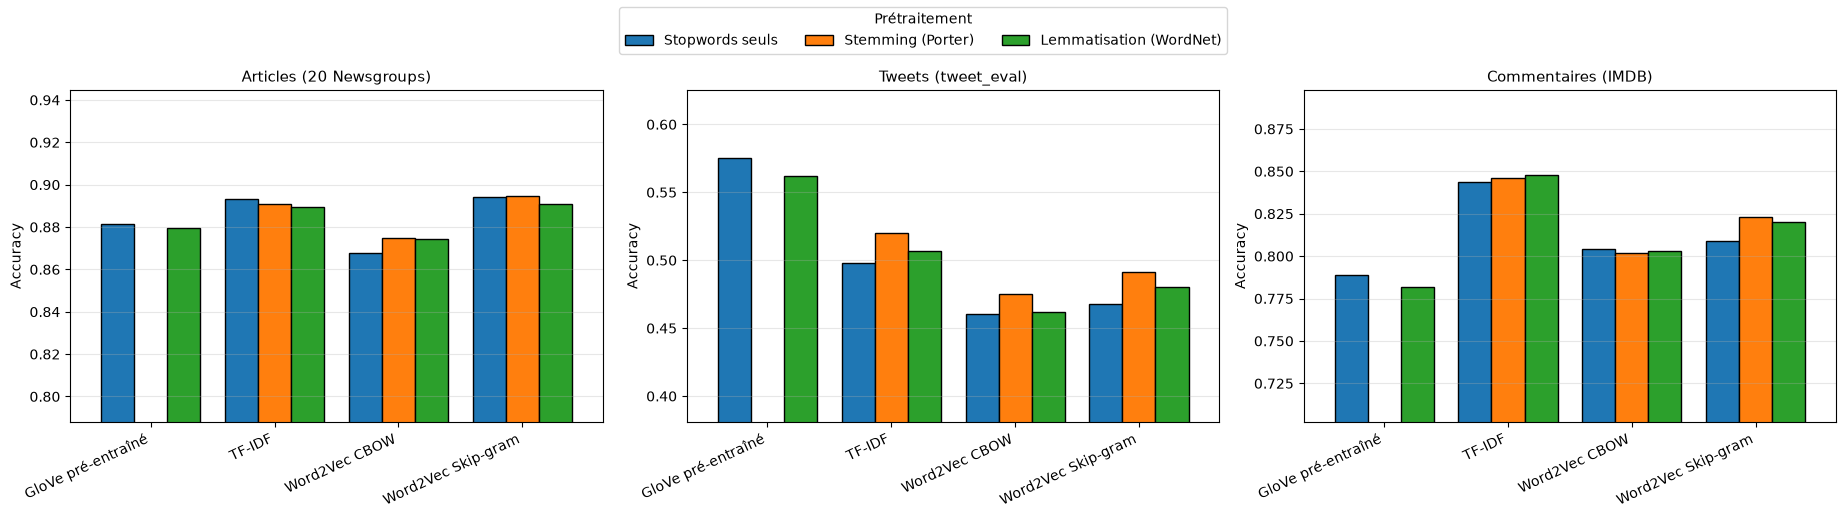

In [20]:
fig, axes = plt.subplots(1, len(jeux), figsize=(6.2 * len(jeux), 5.2), squeeze=False)

for ax, nom in zip(axes[0], jeux):
    sub = accuracy_table.loc[nom]
    sub.plot(kind='bar', ax=ax, edgecolor='black', width=0.8, legend=False)
    ax.set_ylim(max(0, sub.min().min() - 0.08), min(1.0, sub.max().max() + 0.05))
    ax.set_title(nom, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Accuracy')
    ax.tick_params(axis='x', rotation=25)
    for label in ax.get_xticklabels():
        label.set_ha('right')
    ax.grid(axis='y', alpha=0.3)

handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, title='Prétraitement')
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

### Ce que l'on observe

Le graphique montre trois niveaux de difficulté très différents : les barres des articles sont toutes regroupées autour de 87% à 89%, celles des commentaires entre 78% et 85%, et celles des tweets entre 46% et 58%. Les tweets sont aussi le seul jeu où une représentation (GloVe) se détache clairement des autres. Sur les articles, les différences visibles entre barres sont petites.

In [21]:
sg_cbow = []
for nom in jeux:
    a = accuracy_table.loc[nom]
    gap = (a.loc['Word2Vec Skip-gram'] - a.loc['Word2Vec CBOW']).mean()
    sg_cbow.append({'Jeu de données': nom, 'Skip-gram - CBOW (points)': round(gap * 100, 2)})

print("Skip-gram contre CBOW (écart moyen d'accuracy sur les 3 prétraitements):")
display(pd.DataFrame(sg_cbow))

gains = []
for (nom, representation), r in accuracy_table.iterrows():
    gains.append({
        'Jeu de données': nom,
        'Représentation': representation,
        'Stemming - stopwords seuls': round((r[modes['stem']] - r[modes['stop']]) * 100, 2),
        'Lemmatisation - stopwords seuls': round((r[modes['lemma']] - r[modes['stop']]) * 100, 2)
    })

print("\nGain du prétraitement par rapport aux stopwords seuls (en points d'accuracy):")
display(pd.DataFrame(gains))

print("\nAccuracy moyenne par représentation (en%):")
display((results_df.groupby(['Jeu de données', 'Représentation'])['Accuracy'].mean().unstack(0) * 100).round(2))

print("\nAccuracy moyenne par prétraitement (en%), hors GloVe car non testé avec le stemming:")
results_sans_glove = results_df[results_df['Représentation'] != 'GloVe pré-entraîné']
display((results_sans_glove.groupby(['Jeu de données', 'Prétraitement'])['Accuracy'].mean().unstack(0) * 100).loc[order_modes].round(2))

Skip-gram contre CBOW (écart moyen d'accuracy sur les 3 prétraitements):


,Jeu de données,Skip-gram - CBOW (points)
0,Articles (20 Newsgroups),2.10
1,Tweets (tweet_eval),1.38
2,Commentaires (IMDB),1.43



Gain du prétraitement par rapport aux stopwords seuls (en points d'accuracy):


,Jeu de données,Représentation,Stemming - stopwords seuls,Lemmatisation - stopwords seuls
0,Articles (20 Newsgroups),GloVe pré-entraîné,NaN,-0.19
1,Articles (20 Newsgroups),TF-IDF,-0.26,-0.39
2,Articles (20 Newsgroups),Word2Vec CBOW,0.71,0.64
3,Articles (20 Newsgroups),Word2Vec Skip-gram,0.06,-0.32
4,Commentaires (IMDB),GloVe pré-entraîné,NaN,-0.70
5,Commentaires (IMDB),TF-IDF,0.20,0.40
6,Commentaires (IMDB),Word2Vec CBOW,-0.20,-0.10
7,Commentaires (IMDB),Word2Vec Skip-gram,1.40,1.10
8,Tweets (tweet_eval),GloVe pré-entraîné,NaN,-1.33
9,Tweets (tweet_eval),TF-IDF,2.20,0.87



Accuracy moyenne par représentation (en %):


Jeu de données,Articles (20 Newsgroups),Commentaires (IMDB),Tweets (tweet_eval)
Représentation,,,
GloVe pré-entraîné,88.03,78.55,56.87
TF-IDF,89.13,84.60,50.82
Word2Vec CBOW,87.23,80.30,46.60
Word2Vec Skip-gram,89.32,81.73,47.98



Accuracy moyenne par prétraitement (en %), hors GloVe car non testé avec le stemming:


Jeu de données,Articles (20 Newsgroups),Commentaires (IMDB),Tweets (tweet_eval)
Prétraitement,,,
Stopwords seuls,88.51,81.90,47.56
Stemming (Porter),88.68,82.37,49.56
Lemmatisation (WordNet),88.49,82.37,48.29


### Ce que l'on observe

Skip-gram contre CBOW. Skip-gram est meilleur dans les trois jeux : plus 2,10 points en moyenne pour les articles, plus 1,38 pour les tweets et plus 1,43 pour les commentaires. C'est le résultat le plus constant de l'étude. Il est cohérent avec l'idée que Skip-gram apprend mieux les mots rares sur les petits corpus, mais nous ne l'avons pas testé séparément.

Effet du prétraitement. Les gains par rapport aux stopwords seuls dépendent du type de texte.

- Articles : effet nul (de moins 0,4 à plus 0,7 point), dans le bruit.
- Commentaires : effet faible et irrégulier (de moins 0,7 à plus 1,4 point), surtout positif pour Skip-gram.
- Tweets : le stemming améliore les trois représentations apprises sur le corpus (plus 2,20 points pour TF-IDF, plus 2,33 pour Skip-gram, plus 1,47 pour CBOW). La lemmatisation apporte moins (de plus 0,13 à plus 1,20). Pour GloVe, la lemmatisation est légèrement défavorable (moins 1,33).

Moyennes. La moyenne par prétraitement est calculée sans GloVe, qui n'a pas été testé avec le stemming : sur les tweets elle vaut 47,56% avec stopwords seuls, 49,56% avec stemming et 48,29% avec lemmatisation, soit environ 2 points de gain pour le stemming. Sur les articles (88,51%, 88,68%, 88,49%) et les commentaires (81,90%, 82,37%, 82,37%), les moyennes sont très proches. Une explication plausible, non testée, est que sur des textes très courts avec un vocabulaire clairsemé, regrouper les formes d'un même mot aide, alors que sur de longs textes les mots importants apparaissent déjà assez souvent.

Articles (20 Newsgroups)
Meilleure configuration: Word2Vec Skip-gram + Stemming (Porter)
Accuracy = 89.47%, F1 macro = 89.51%
Marge d'erreur à 95 % sur l'accuracy (n_test = 1558): plus ou moins 1.5 points
Configurations à moins de 1.5 points de la meilleure: 7 sur 11

                       precision    recall  f1-score   support

        comp.graphics       0.92      0.87      0.89       389
     rec.sport.hockey       0.95      0.91      0.93       399
            sci.space       0.83      0.88      0.86       394
talk.politics.mideast       0.89      0.91      0.90       376

             accuracy                           0.89      1558
            macro avg       0.90      0.89      0.90      1558
         weighted avg       0.90      0.89      0.90      1558

Tweets (tweet_eval)
Meilleure configuration: GloVe pré-entraîné + Stopwords seuls
Accuracy = 57.53%, F1 macro = 56.46%
Marge d'erreur à 95 % sur l'accuracy (n_test = 1500): plus ou moins 2.5 points
Configurations à moins de 

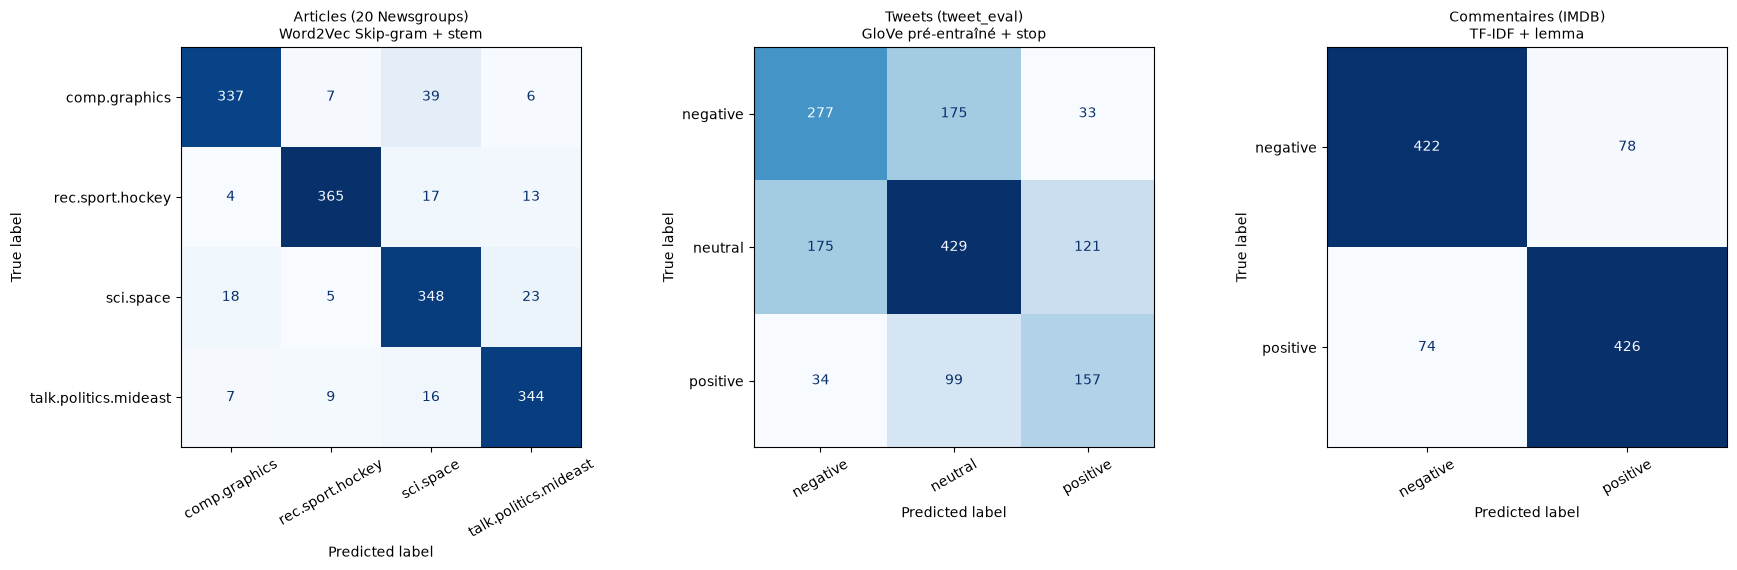

In [22]:
fig, axes = plt.subplots(1, len(jeux), figsize=(6 * len(jeux), 5.6), squeeze=False)

for ax, (nom, (X_train, y_train, X_test, y_test, target_names)) in zip(axes[0], jeux.items()):
    sub = results_df[results_df['Jeu de données'] == nom].sort_values('Accuracy', ascending=False)
    best = sub.iloc[0]
    p = best['Accuracy']
    margin = 1.96 * np.sqrt(p * (1 - p) / len(y_test)) * 100

    print("=" * 80)
    print(nom)
    print("=" * 80)
    print(f"Meilleure configuration: {best['Représentation']} + {best['Prétraitement']}")
    print(f"Accuracy = {p:.2%}, F1 macro = {best['F1 macro']:.2%}")
    print(f"Marge d'erreur à 95% sur l'accuracy (n_test = {len(y_test)}): plus ou moins {margin:.1f} points")
    n_close = int((sub['Accuracy'] >= p - margin / 100).sum())
    print(f"Configurations à moins de {margin:.1f} points de la meilleure: {n_close} sur {len(sub)}\n")

    y_best = predictions[(nom, best['Représentation'], best['mode'])]
    print(classification_report(y_test, y_best, target_names=target_names))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_best, display_labels=target_names,
        xticks_rotation=30, cmap='Blues', ax=ax, colorbar=False
    )
    ax.set_title(f"{nom}\n{best['Représentation']} + {best['mode']}", fontsize=10)

plt.tight_layout()
plt.show()

### Ce que l'on observe : fiabilité des écarts

La marge d'erreur à 95% sur l'accuracy est d'environ 1,5 point pour les articles, 2,2 points pour les commentaires et 2,5 points pour les tweets. Elle permet de savoir quelles différences sont significatives.

- Articles : 7 configurations sur 11 sont à moins de 1,5 point de la meilleure. Les classer entre elles n'a pas de sens, elles sont équivalentes. Dans le rapport de classification de la meilleure, la classe sci.space est la plus difficile (précision de 0,83) et rec.sport.hockey la plus facile (F1 de 0,93).
- Tweets : seules 2 configurations sur 11 sont proches de la meilleure (GloVe avec stopwords seuls et GloVe avec lemmatisation). L'avantage de GloVe est donc significatif. Les précisions et rappels par classe sont proches de 0,5 à 0,6, avec la classe positive la moins bien reconnue.
- Commentaires : 3 configurations sur 11 sont proches de la meilleure, ce sont les trois variantes de TF-IDF. La supériorité de TF-IDF est donc cohérente sur ce jeu. Les deux classes sont reconnues avec la même qualité (0,85).

## 7. Conclusion

Chaque partie ci-dessus est suivie de ses observations détaillées. Cette section reprend uniquement ce qui se répète d'un jeu de données à l'autre.

### Ce qui se confirme sur les trois jeux

- Skip-gram est meilleur que CBOW dans les neuf comparaisons.
- Word2Vec appris sur notre corpus ne bat jamais TF-IDF de façon nette : égalité sur les articles, TF-IDF devant sur les commentaires et sur les tweets.
- Le jeu de données compte plus que la méthode : environ 89% sur les articles, 85% sur les commentaires et au mieux 58% sur les tweets, avec très peu d'écart entre méthodes sur les articles.

### Ce qui dépend du type de texte

- Les embeddings pré-entraînés (GloVe) sont la meilleure représentation sur les tweets, courts et bruités, mais pas sur les articles ni sur les commentaires, plus longs.
- Le stemming n'apporte un gain visible (environ 2 points) que sur les tweets, dont le vocabulaire est très clairsemé. Sur les articles et les commentaires, le prétraitement ne change pas significativement les résultats.

### Limites et pistes

- Un seul découpage train/test et un sous-échantillonnage des tweets et des critiques : une validation croisée donnerait des écarts plus fiables.
- Pour les tweets, la répartition des classes diffère entre train et test : pondérer les classes ou rééquilibrer le train serait à tester.
- Moyenne simple des vecteurs de mots : on pourrait pondérer par TF-IDF, ou utiliser Doc2Vec ou des modèles contextuels comme BERT.
- Un seul classifieur (régression logistique), hyperparamètres de Word2Vec non réglés, emojis, hashtags et fautes d'orthographe des tweets perdus par le prétraitement.